# BÀI THỰC HÀNH SỐ 2 - PHẦN V - BÀI 2 (Trang 32)
## Tính giá trị F-measure của các bài tập cơ bản (ID3, CART & Naïve Bayes)

- **Họ tên sinh viên:** `Nguyễn Phạm Bảo Khanh`
- **MSSV:** `6451071033`
- **Môn học:** Khai phá dữ liệu (Data Mining)
- **Mục tiêu:** Cài đặt và thực thi hoàn chỉnh 3 giải thuật phân lớp **ID3** (*Information Gain*), **CART** (*Multi-way Categorical Gini Index* theo tài liệu thực hành) và **Naïve Bayes** (làm trơn Laplace $\alpha = 1$), từ đó lập ma trận nhầm lẫn và tính **Precision**, **Recall** và **F-measure** ($F_1 = \frac{2 \times \text{Precision} \times \text{Recall}}{\text{Precision} + \text{Recall}}$) cho cả 3 bài tập cơ bản:
  1. **Bài mẫu III.1 (Trang 1–15):** Đánh giá rủi ro hồ sơ vay tín dụng (*Credit Risk*).
  2. **Bài 1 — Phần IV (Trang 23–25):** Dự đoán doanh số đồ chơi (*Doanh số bán*).
  3. **Bài 2 — Phần IV (Trang 25–26):** Phân tích cảm xúc (*Sentiment Analysis*).

In [1]:
import math
import itertools
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from sklearn.metrics import confusion_matrix, precision_recall_fscore_support

STUDENT_NAME = "Nguyễn Phạm Bảo Khanh"
MSSV = "6451071033"
print(f"{STUDENT_NAME} - {MSSV}")

# Cấu hình hiển thị bảng và đồ thị hỗ trợ đầy đủ tiếng Việt
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 1000)
pd.set_option("display.precision", 4)
sns.set_theme(style="whitegrid")
plt.rcParams["font.sans-serif"] = ["Segoe UI", "Arial", "DejaVu Sans"]
plt.rcParams["axes.unicode_minus"] = False


def check_contradictions(df: pd.DataFrame, target_col: str) -> pd.DataFrame:
    """Kiểm tra mâu thuẫn: các dòng có cùng thuộc tính đầu vào nhưng khác nhãn lớp."""
    features = [c for c in df.columns if c != target_col]
    grouped = df.groupby(features, dropna=False)[target_col].nunique()
    conflicting_keys = grouped[grouped > 1].index
    if len(conflicting_keys) == 0:
        return pd.DataFrame(columns=df.columns)
    key_df = pd.DataFrame(list(conflicting_keys), columns=features)
    return df.merge(key_df, on=features, how="inner")


def entropy(labels) -> float:
    """Tính độ bất định Entropy E(S) = -sum(p_j * log2(p_j))."""
    n = len(labels)
    if n == 0:
        return 0.0
    counts = Counter(labels)
    return -sum((c / n) * math.log2(c / n) for c in counts.values() if c > 0)


def gini_impurity(labels) -> float:
    """Tính chỉ số Gini(S) = 1 - sum(p_j^2)."""
    n = len(labels)
    if n == 0:
        return 0.0
    counts = Counter(labels)
    return 1.0 - sum((c / n) ** 2 for c in counts.values())


def compute_split_metrics(df: pd.DataFrame, features: list, target_col: str) -> pd.DataFrame:
    """Tính Entropy sau chia, Information Gain (ID3) và Gini Index (CART đa nhánh) cho từng thuộc tính."""
    n = len(df)
    base_ent = entropy(df[target_col])
    base_gini = gini_impurity(df[target_col])
    rows = []
    for feat in features:
        weighted_ent = 0.0
        weighted_gini = 0.0
        branch_details = []
        for val, sub in df.groupby(feat, sort=False):
            w = len(sub) / n
            e_sub = entropy(sub[target_col])
            g_sub = gini_impurity(sub[target_col])
            weighted_ent += w * e_sub
            weighted_gini += w * g_sub
            cnt_str = ", ".join(f"{k}:{v}" for k, v in Counter(sub[target_col]).items())
            branch_details.append(f"{val} ({len(sub)} mẫu: {cnt_str}; E={e_sub:.3f}, Gini={g_sub:.3f})")
        rows.append({
            "Thuộc tính": feat,
            "Entropy sau chia": weighted_ent,
            "Information Gain (ID3)": base_ent - weighted_ent,
            "Gini Index (CART)": weighted_gini,
            "Giảm Gini": base_gini - weighted_gini,
            "Chi tiết các nhánh": " | ".join(branch_details),
        })
    return pd.DataFrame(rows)


class CategoricalDecisionTree:
    """Cây quyết định phân loại đa nhánh hỗ trợ ID3 (Information Gain) và CART (Gini Index)."""

    def __init__(self, criterion: str = "id3", tie_overrides: dict | None = None, class_order: list | None = None):
        if criterion not in ("id3", "cart"):
            raise ValueError("criterion phải là 'id3' hoặc 'cart'")
        self.criterion = criterion
        self.tie_overrides = tie_overrides or {}
        self.class_order = class_order
        self.tree_ = None
        self.ties_log_ = []
        self.split_tables_ = {}
        self.unseen_fallbacks_ = []

    def _majority_class(self, labels) -> str:
        counts = Counter(labels)
        if self.class_order:
            return max(
                counts.keys(),
                key=lambda c: (counts[c], -self.class_order.index(c) if c in self.class_order else -999),
            )
        return counts.most_common(1)[0][0]

    def fit(self, df: pd.DataFrame, target_col: str):
        features = [c for c in df.columns if c != target_col]
        self.ties_log_ = []
        self.split_tables_ = {}
        self.tree_ = self._build(df, features, target_col, path="Root")
        return self

    def _build(self, df: pd.DataFrame, features: list, target_col: str, path: str):
        labels = list(df[target_col])
        counts = dict(Counter(labels))
        majority = self._majority_class(labels)

        if len(counts) == 1:
            return {"leaf": True, "label": labels[0], "n": len(labels), "counts": counts}
        if not features:
            return {"leaf": True, "label": majority, "n": len(labels), "counts": counts}

        metrics_df = compute_split_metrics(df, features, target_col)
        self.split_tables_[path] = metrics_df

        score_col = "Information Gain (ID3)" if self.criterion == "id3" else "Gini Index (CART)"
        best_score = metrics_df[score_col].max() if self.criterion == "id3" else metrics_df[score_col].min()
        tied = list(metrics_df.loc[(metrics_df[score_col] - best_score).abs() < 1e-12, "Thuộc tính"])

        chosen = tied[0]  # Quy tắc phá hòa mặc định: ưu tiên thuộc tính đứng trước theo thứ tự cột
        tie_reason = "Mặc định theo thứ tự cột"
        if path in self.tie_overrides and self.tie_overrides[path] in tied:
            chosen = self.tie_overrides[path]
            tie_reason = "Theo hướng dẫn trong tài liệu"

        if len(tied) > 1:
            self.ties_log_.append({
                "Nút": path,
                "Thuật toán": self.criterion.upper(),
                "Điểm tốt nhất": round(best_score, 4),
                "Các thuộc tính đồng hạng": ", ".join(tied),
                "Thuộc tính được chọn": chosen,
                "Quy tắc": tie_reason,
            })

        rem_features = [f for f in features if f != chosen]
        branches = {}
        for val, sub in df.groupby(chosen, sort=False):
            branches[val] = self._build(sub, rem_features, target_col, f"{path} -> {chosen}={val}")

        return {
            "leaf": False,
            "feature": chosen,
            "score": best_score,
            "n": len(labels),
            "counts": counts,
            "majority": majority,
            "branches": branches,
        }

    def predict_one(self, row: pd.Series):
        node = self.tree_
        path_steps = []
        while not node["leaf"]:
            feat = node["feature"]
            val = row[feat]
            if val in node["branches"]:
                path_steps.append(f"{feat}={val}")
                node = node["branches"][val]
            else:
                self.unseen_fallbacks_.append((feat, val, node["majority"]))
                path_steps.append(f"{feat}={val} [nhánh chưa thấy -> đa số: {node['majority']}]")
                return node["majority"], " -> ".join(path_steps)
        return node["label"], " -> ".join(path_steps)

    def predict(self, df_test: pd.DataFrame) -> list:
        self.unseen_fallbacks_ = []
        return [self.predict_one(row)[0] for _, row in df_test.iterrows()]

    def predict_with_paths(self, df_test: pd.DataFrame):
        self.unseen_fallbacks_ = []
        preds, paths = [], []
        for _, row in df_test.iterrows():
            pred, path = self.predict_one(row)
            preds.append(pred)
            paths.append(path)
        return preds, paths

    def format_tree(self, node=None, prefix="", is_last=True, branch_label=None) -> str:
        if node is None:
            node = self.tree_
        lines = []
        connector = "" if branch_label is None else ("└── " if is_last else "├── ")
        label_prefix = "" if branch_label is None else f"[{branch_label}] "
        if node["leaf"]:
            lines.append(f"{prefix}{connector}{label_prefix}=> LÁ: {node['label']} (n={node['n']}, {node['counts']})")
            return "\n".join(lines)
        metric_name = "Gain" if self.criterion == "id3" else "Gini"
        lines.append(
            f"{prefix}{connector}{label_prefix}<{node['feature']}> ({metric_name}={node['score']:.4f}, n={node['n']}, {node['counts']})"
        )
        child_prefix = prefix + ("" if branch_label is None else ("    " if is_last else "│   "))
        items = list(node["branches"].items())
        for idx, (val, child) in enumerate(items):
            lines.append(self.format_tree(child, child_prefix, idx == len(items) - 1, f"{node['feature']} = {val}"))
        return "\n".join(lines)

    def extract_rules(self, node=None, conditions=None) -> list:
        if node is None:
            node = self.tree_
        if conditions is None:
            conditions = []
        if node["leaf"]:
            cond_str = " AND ".join(conditions)
            return [f"IF {cond_str} THEN {node['label']} (n={node['n']})"]
        rules = []
        for val, child in node["branches"].items():
            rules.extend(self.extract_rules(child, conditions + [f"{node['feature']} = '{val}'"]))
        return rules


class CategoricalLaplaceNB:
    """Naïve Bayes phân loại với làm trơn Laplace (alpha=1) cho cả tiên nghiệm và xác suất có điều kiện."""

    def __init__(self, alpha: float = 1.0, class_order: list | None = None):
        self.alpha = alpha
        self.class_order = class_order
        self.classes_ = []
        self.features_ = []
        self.vocab_sizes_ = {}
        self.class_counts_ = {}
        self.priors_ = {}
        self.likelihoods_ = {}

    def fit(self, df_train: pd.DataFrame, target_col: str):
        self.features_ = [c for c in df_train.columns if c != target_col]
        unique_classes = list(dict.fromkeys(df_train[target_col]))
        self.classes_ = [c for c in self.class_order if c in unique_classes] if self.class_order else unique_classes
        n = len(df_train)
        num_classes = len(self.classes_)
        self.vocab_sizes_ = {f: df_train[f].nunique() for f in self.features_}

        self.class_counts_ = {}
        self.priors_ = {}
        self.likelihoods_ = {}
        for cls in self.classes_:
            sub = df_train[df_train[target_col] == cls]
            nc = len(sub)
            self.class_counts_[cls] = nc
            self.priors_[cls] = (nc + self.alpha) / (n + self.alpha * num_classes)
            self.likelihoods_[cls] = {}
            for f in self.features_:
                v_size = self.vocab_sizes_[f]
                val_counts = sub[f].value_counts().to_dict()
                self.likelihoods_[cls][f] = {
                    val: (val_counts.get(val, 0) + self.alpha) / (nc + self.alpha * v_size)
                    for val in df_train[f].unique()
                }
                self.likelihoods_[cls][f]["__default__"] = self.alpha / (nc + self.alpha * v_size)
        return self

    def predict_detail(self, df_test: pd.DataFrame) -> pd.DataFrame:
        rows = []
        for step, (_, row) in enumerate(df_test.iterrows(), start=1):
            numerators = {}
            for cls in self.classes_:
                p = self.priors_[cls]
                for f in self.features_:
                    p *= self.likelihoods_[cls][f].get(row[f], self.likelihoods_[cls][f]["__default__"])
                numerators[cls] = p
            total = sum(numerators.values())
            pred = max(self.classes_, key=lambda c: numerators[c])
            rec = {"Mẫu": step}
            for cls in self.classes_:
                rec[f"Tử số P(X|{cls})P({cls})"] = numerators[cls]
            for cls in self.classes_:
                rec[f"P({cls}|X) chuẩn hóa"] = numerators[cls] / total if total > 0 else 0.0
            rec["Dự đoán NB"] = pred
            rows.append(rec)
        return pd.DataFrame(rows)

    def predict(self, df_test: pd.DataFrame) -> list:
        return list(self.predict_detail(df_test)["Dự đoán NB"])


def evaluate_predictions(y_true: list, y_pred: list, labels: list, pos_label: str | None = None):
    """Tính Confusion Matrix, Precision, Recall, F-measure từng lớp, Macro F1 và Weighted F1."""
    cm = confusion_matrix(y_true, y_pred, labels=labels)
    p_arr, r_arr, f1_arr, sup_arr = precision_recall_fscore_support(
        y_true, y_pred, labels=labels, zero_division=0
    )
    # Kiểm chứng công thức F-measure = 2 * P * R / (P + R)
    manual_f1 = [
        (2 * p * r / (p + r)) if (p + r) > 0 else 0.0
        for p, r in zip(p_arr, r_arr)
    ]
    assert np.allclose(f1_arr, manual_f1, atol=1e-12)

    per_class_df = pd.DataFrame({
        "Lớp": labels,
        "Precision": p_arr,
        "Recall": r_arr,
        "F-measure (F1)": f1_arr,
        "Support": sup_arr,
    })

    p_macro, r_macro, f1_macro, _ = precision_recall_fscore_support(
        y_true, y_pred, labels=labels, average="macro", zero_division=0
    )
    _, _, f1_weighted, _ = precision_recall_fscore_support(
        y_true, y_pred, labels=labels, average="weighted", zero_division=0
    )
    acc = sum(yt == yp for yt, yp in zip(y_true, y_pred)) / len(y_true)

    pos_metrics = {}
    if pos_label is not None and pos_label in labels:
        idx = labels.index(pos_label)
        pos_metrics = {
            "pos_label": pos_label,
            "pos_precision": float(p_arr[idx]),
            "pos_recall": float(r_arr[idx]),
            "pos_f1": float(f1_arr[idx]),
        }

    summary = {
        "Accuracy": float(acc),
        "Macro Precision": float(p_macro),
        "Macro Recall": float(r_macro),
        "Macro F1": float(f1_macro),
        "Weighted F1": float(f1_weighted),
        **pos_metrics,
    }
    return cm, per_class_df, summary


def plot_confusion_matrices(cm_dict: dict, labels: list, title: str, cmap: str = "Blues"):
    """Vẽ lưới ma trận nhầm lẫn cho các mô hình trên cùng một bài tập."""
    n_models = len(cm_dict)
    fig, axes = plt.subplots(1, n_models, figsize=(5.2 * n_models, 4.3))
    if n_models == 1:
        axes = [axes]
    for ax, (model_name, info) in zip(axes, cm_dict.items()):
        cm = info["cm"]
        subtitle = info.get("subtitle", "")
        sns.heatmap(
            cm,
            annot=True,
            fmt="d",
            cmap=cmap,
            cbar=False,
            xticklabels=labels,
            yticklabels=labels,
            linewidths=0.8,
            linecolor="gray",
            annot_kws={"size": 12, "weight": "bold"},
            ax=ax,
        )
        ax.set_title(f"{model_name}\n{subtitle}", fontsize=11, fontweight="bold", pad=10)
        ax.set_xlabel("Dự đoán (Predicted)", fontsize=10)
        ax.set_ylabel("Thực tế (Actual)", fontsize=10)
        ax.tick_params(axis="x", rotation=15)
        ax.tick_params(axis="y", rotation=0)
    fig.suptitle(title, fontsize=13, fontweight="bold", y=1.03)
    plt.tight_layout()
    plt.show()


Nguyễn Phạm Bảo Khanh - 6451071033


---
## Phần 1: Bài mẫu III.1 (Trang 1–15) — Đánh giá rủi ro hồ sơ vay tín dụng (*Credit Risk*)

- **Dữ liệu huấn luyện:** 15 hồ sơ gồm 4 thuộc tính điều kiện (`Thu nhập`, `Nghề nghiệp`, `Tình trạng hôn nhân`, `Sở hữu nhà`) và thuộc tính quyết định `Nguy cơ` (`Rủi ro thấp`: 9 mẫu, `Rủi ro cao`: 6 mẫu).
- **Dữ liệu kiểm thử (Yêu cầu 4–5):** 3 hồ sơ với nhãn thực tế lần lượt là `['Rủi ro cao', 'Rủi ro thấp', 'Rủi ro thấp']`.
- **Lớp dương (Positive class):** Theo hướng dẫn trang 11 và 15, lớp dương là **`Rủi ro thấp`**, lớp âm là **`Rủi ro cao`**.

In [2]:
print(f"{STUDENT_NAME} - {MSSV}")

# Dữ liệu huấn luyện và kiểm thử Bài mẫu III.1 (Trang 1-2)
credit_cols = ["Thu nhập", "Nghề nghiệp", "Tình trạng hôn nhân", "Sở hữu nhà", "Nguy cơ"]
df_credit_train = pd.DataFrame([
    ["Thấp", "Vận tải", "Độc thân", "Rồi", "Rủi ro cao"],
    ["Thấp", "Vận tải", "Độc thân", "Chưa", "Rủi ro cao"],
    ["Cao", "Vận tải", "Độc thân", "Rồi", "Rủi ro thấp"],
    ["Trung bình", "Truyền thông", "Độc thân", "Rồi", "Rủi ro thấp"],
    ["Trung bình", "Kinh doanh", "Đã kết hôn", "Rồi", "Rủi ro thấp"],
    ["Trung bình", "Kinh doanh", "Đã kết hôn", "Chưa", "Rủi ro cao"],
    ["Cao", "Kinh doanh", "Đã kết hôn", "Chưa", "Rủi ro thấp"],
    ["Thấp", "Truyền thông", "Độc thân", "Rồi", "Rủi ro cao"],
    ["Thấp", "Kinh doanh", "Đã kết hôn", "Rồi", "Rủi ro thấp"],
    ["Trung bình", "Truyền thông", "Đã kết hôn", "Rồi", "Rủi ro thấp"],
    ["Thấp", "Truyền thông", "Đã kết hôn", "Chưa", "Rủi ro thấp"],
    ["Cao", "Truyền thông", "Độc thân", "Chưa", "Rủi ro thấp"],
    ["Cao", "Vận tải", "Đã kết hôn", "Rồi", "Rủi ro thấp"],
    ["Trung bình", "Truyền thông", "Độc thân", "Chưa", "Rủi ro cao"],
    ["Cao", "Kinh doanh", "Độc thân", "Rồi", "Rủi ro cao"],
], columns=credit_cols)

df_credit_test = pd.DataFrame([
    ["Trung bình", "Vận tải", "Độc thân", "Rồi"],
    ["Cao", "Truyền thông", "Độc thân", "Rồi"],
    ["Thấp", "Vận tải", "Đã kết hôn", "Rồi"],
], columns=credit_cols[:-1])

y_credit_true = ["Rủi ro cao", "Rủi ro thấp", "Rủi ro thấp"]
credit_labels = ["Rủi ro thấp", "Rủi ro cao"]  # Lớp dương đứng trước

# 1. Kiểm tra mâu thuẫn
conflicts_credit = check_contradictions(df_credit_train, "Nguy cơ")
print(f"Số dòng mâu thuẫn trong dữ liệu Credit Risk: {len(conflicts_credit)}")
print("Phân bố lớp tập huấn luyện:", dict(Counter(df_credit_train["Nguy cơ"])))
print(f"Entropy gốc E(S) = {entropy(df_credit_train['Nguy cơ']):.4f} | Gini gốc Gini(S) = {gini_impurity(df_credit_train['Nguy cơ']):.4f}")

# 2. Huấn luyện ID3 & CART (tài liệu p.6 chọn Thu nhập cho ID3, p.9 chọn Sở hữu nhà cho CART ở nhánh Đã kết hôn)
id3_credit = CategoricalDecisionTree("id3", class_order=credit_labels).fit(df_credit_train, "Nguy cơ")
cart_credit = CategoricalDecisionTree(
    "cart",
    tie_overrides={"Root -> Tình trạng hôn nhân=Đã kết hôn": "Sở hữu nhà"},
    class_order=credit_labels,
).fit(df_credit_train, "Nguy cơ")

print("\n--- Bảng Information Gain (ID3) & Gini Index (CART) tại Nút gốc ---")
display(id3_credit.split_tables_["Root"].drop(columns=["Chi tiết các nhánh"]))
print("Ghi chú toán học (Trang 8): Gini_Tình trạng hôn nhân(S) = (8/15)*0.46875 + (7/15)*0.24490 = 0.3643 (tài liệu PDF in nhầm thành 0,403, nhưng vẫn là giá trị nhỏ nhất nên cùng chọn 'Tình trạng hôn nhân').")

print("\n--- Các nút xảy ra đồng hạng (Tie-breaking) ---")
display(pd.DataFrame(id3_credit.ties_log_ + cart_credit.ties_log_))

print("\n--- Cây quyết định ID3 ---")
print(id3_credit.format_tree())

print("\n--- Cây quyết định CART (theo trang 9-10 tài liệu) ---")
print(cart_credit.format_tree())

# Xác suất bổ sung (Yêu cầu 6, 7)
p_truyen_thong = (df_credit_train["Nghề nghiệp"] == "Truyền thông").mean()
sub_rrc = df_credit_train[df_credit_train["Nguy cơ"] == "Rủi ro cao"]
p_thap_given_rrc = (sub_rrc["Thu nhập"] == "Thấp").mean()
print(f"\nYêu cầu 6: P(Nghề nghiệp = 'Truyền thông') = {(df_credit_train['Nghề nghiệp'] == 'Truyền thông').sum()}/{len(df_credit_train)} = {p_truyen_thong:.4f}")
print(f"Yêu cầu 7: P(Thu nhập = 'Thấp' | Nguy cơ = 'Rủi ro cao') = {(sub_rrc['Thu nhập'] == 'Thấp').sum()}/{len(sub_rrc)} = {p_thap_given_rrc:.4f}")


Nguyễn Phạm Bảo Khanh - 6451071033
Số dòng mâu thuẫn trong dữ liệu Credit Risk: 0
Phân bố lớp tập huấn luyện: {'Rủi ro cao': 6, 'Rủi ro thấp': 9}
Entropy gốc E(S) = 0.9710 | Gini gốc Gini(S) = 0.4800

--- Bảng Information Gain (ID3) & Gini Index (CART) tại Nút gốc ---


,Thuộc tính,Entropy sau chia,Information Gain (ID3),Gini Index (CART),Giảm Gini
0,Thu nhập,0.8879,0.0830,0.4267,0.0533
1,Nghề nghiệp,0.9576,0.0133,0.4711,0.0089
2,Tình trạng hôn nhân,0.7851,0.1858,0.3643,0.1157
3,Sở hữu nhà,0.9510,0.0200,0.4667,0.0133


Ghi chú toán học (Trang 8): Gini_Tình trạng hôn nhân(S) = (8/15)*0.46875 + (7/15)*0.24490 = 0.3643 (tài liệu PDF in nhầm thành 0,403, nhưng vẫn là giá trị nhỏ nhất nên cùng chọn 'Tình trạng hôn nhân').

--- Các nút xảy ra đồng hạng (Tie-breaking) ---


,Nút,Thuật toán,Điểm tốt nhất,Các thuộc tính đồng hạng,Thuộc tính được chọn,Quy tắc
0,Root -> Tình trạng hôn nhân=Đã kết hôn,ID3,0.1981,"Thu nhập, Sở hữu nhà",Thu nhập,Mặc định theo thứ tự cột
1,Root -> Tình trạng hôn nhân=Đã kết hôn,CART,0.1905,"Thu nhập, Sở hữu nhà",Sở hữu nhà,Theo hướng dẫn trong tài liệu



--- Cây quyết định ID3 ---
<Tình trạng hôn nhân> (Gain=0.1858, n=15, {'Rủi ro cao': 6, 'Rủi ro thấp': 9})
├── [Tình trạng hôn nhân = Độc thân] <Thu nhập> (Gain=0.3601, n=8, {'Rủi ro cao': 5, 'Rủi ro thấp': 3})
│   ├── [Thu nhập = Thấp] => LÁ: Rủi ro cao (n=3, {'Rủi ro cao': 3})
│   ├── [Thu nhập = Cao] <Nghề nghiệp> (Gain=0.9183, n=3, {'Rủi ro thấp': 2, 'Rủi ro cao': 1})
│   │   ├── [Nghề nghiệp = Vận tải] => LÁ: Rủi ro thấp (n=1, {'Rủi ro thấp': 1})
│   │   ├── [Nghề nghiệp = Truyền thông] => LÁ: Rủi ro thấp (n=1, {'Rủi ro thấp': 1})
│   │   └── [Nghề nghiệp = Kinh doanh] => LÁ: Rủi ro cao (n=1, {'Rủi ro cao': 1})
│   └── [Thu nhập = Trung bình] <Sở hữu nhà> (Gain=1.0000, n=2, {'Rủi ro thấp': 1, 'Rủi ro cao': 1})
│       ├── [Sở hữu nhà = Rồi] => LÁ: Rủi ro thấp (n=1, {'Rủi ro thấp': 1})
│       └── [Sở hữu nhà = Chưa] => LÁ: Rủi ro cao (n=1, {'Rủi ro cao': 1})
└── [Tình trạng hôn nhân = Đã kết hôn] <Thu nhập> (Gain=0.1981, n=7, {'Rủi ro thấp': 6, 'Rủi ro cao': 1})
    ├── [Thu nhập 

In [3]:
print(f"{STUDENT_NAME} - {MSSV}")

# 3. Huấn luyện Naïve Bayes làm trơn Laplace (alpha=1) & dự đoán trên 3 hồ sơ kiểm thử
nb_credit = CategoricalLaplaceNB(alpha=1.0, class_order=credit_labels).fit(df_credit_train, "Nguy cơ")
print("Tiên nghiệm Laplace P(c) = (N_c + 1)/(15 + 2):", {k: round(v, 4) for k, v in nb_credit.priors_.items()})
print("Kích thước tập giá trị |V_i|:", nb_credit.vocab_sizes_)

pred_id3_credit, path_id3_credit = id3_credit.predict_with_paths(df_credit_test)
pred_cart_credit, path_cart_credit = cart_credit.predict_with_paths(df_credit_test)
nb_detail_credit = nb_credit.predict_detail(df_credit_test)
pred_nb_credit = list(nb_detail_credit["Dự đoán NB"])

print("\n--- Chi tiết xác suất Naïve Bayes (đối chiếu PDF trang 12–15) ---")
display(nb_detail_credit)

compare_credit_df = df_credit_test.copy()
compare_credit_df["Thực tế"] = y_credit_true
compare_credit_df["Dự đoán ID3"] = pred_id3_credit
compare_credit_df["Dự đoán CART"] = pred_cart_credit
compare_credit_df["Dự đoán Naïve Bayes"] = pred_nb_credit
print("\n--- Bảng đối chiếu dự đoán trên tập kiểm thử Credit Risk ---")
display(compare_credit_df)

# 4. Đánh giá Confusion Matrix, Precision, Recall, F-measure
credit_results = {}
credit_cm_plots = {}
for mname, y_pred in [("ID3", pred_id3_credit), ("CART", pred_cart_credit), ("Naïve Bayes", pred_nb_credit)]:
    cm, per_cls, summ = evaluate_predictions(y_credit_true, y_pred, credit_labels, pos_label="Rủi ro thấp")
    credit_results[mname] = (cm, per_cls, summ)
    credit_cm_plots[mname] = {
        "cm": cm,
        "subtitle": f"F1('Rủi ro thấp')={summ['pos_f1']:.4f} | Macro F1={summ['Macro F1']:.4f}",
    }
    print(f"\n=== Kết quả {mname} (Credit Risk) ===")
    display(per_cls)
    print(
        f"Lớp dương 'Rủi ro thấp': Precision = {summ['pos_precision']:.4f}, "
        f"Recall = {summ['pos_recall']:.4f}, F-measure = {summ['pos_f1']:.4f} | "
        f"Accuracy = {summ['Accuracy']:.4f}, Macro F1 = {summ['Macro F1']:.4f}"
    )

# Kiểm chứng khớp hoàn toàn với PDF trang 11 & 15
assert math.isclose(credit_results["CART"][2]["pos_precision"], 2 / 3, rel_tol=1e-9)
assert math.isclose(credit_results["CART"][2]["pos_recall"], 1.0, rel_tol=1e-9)
assert math.isclose(credit_results["CART"][2]["pos_f1"], 0.80, rel_tol=1e-9)
assert math.isclose(credit_results["Naïve Bayes"][2]["pos_precision"], 1.0, rel_tol=1e-9)
assert math.isclose(credit_results["Naïve Bayes"][2]["pos_recall"], 1.0, rel_tol=1e-9)
assert math.isclose(credit_results["Naïve Bayes"][2]["pos_f1"], 1.0, rel_tol=1e-9)
print("\n[ĐÃ KIỂM CHỨNG] Kết quả CART (P=2/3, R=1.0, F1=0.80) và Naïve Bayes (P=1.0, R=1.0, F1=1.0) khớp 100% tài liệu PDF trang 11 & 15.")


Nguyễn Phạm Bảo Khanh - 6451071033
Tiên nghiệm Laplace P(c) = (N_c + 1)/(15 + 2): {'Rủi ro thấp': 0.5882, 'Rủi ro cao': 0.4118}
Kích thước tập giá trị |V_i|: {'Thu nhập': 3, 'Nghề nghiệp': 3, 'Tình trạng hôn nhân': 2, 'Sở hữu nhà': 2}

--- Chi tiết xác suất Naïve Bayes (đối chiếu PDF trang 12–15) ---


,Mẫu,Tử số P(X|Rủi ro thấp)P(Rủi ro thấp),Tử số P(X|Rủi ro cao)P(Rủi ro cao),P(Rủi ro thấp|X) chuẩn hóa,P(Rủi ro cao|X) chuẩn hóa,Dự đoán NB
0,1,0.0113,0.0172,0.3980,0.6020,Rủi ro cao
1,2,0.0236,0.0114,0.6739,0.3261,Rủi ro thấp
2,3,0.0149,0.0076,0.6613,0.3387,Rủi ro thấp



--- Bảng đối chiếu dự đoán trên tập kiểm thử Credit Risk ---


,Thu nhập,Nghề nghiệp,Tình trạng hôn nhân,Sở hữu nhà,Thực tế,Dự đoán ID3,Dự đoán CART,Dự đoán Naïve Bayes
0,Trung bình,Vận tải,Độc thân,Rồi,Rủi ro cao,Rủi ro thấp,Rủi ro thấp,Rủi ro cao
1,Cao,Truyền thông,Độc thân,Rồi,Rủi ro thấp,Rủi ro thấp,Rủi ro thấp,Rủi ro thấp
2,Thấp,Vận tải,Đã kết hôn,Rồi,Rủi ro thấp,Rủi ro thấp,Rủi ro thấp,Rủi ro thấp



=== Kết quả ID3 (Credit Risk) ===


,Lớp,Precision,Recall,F-measure (F1),Support
0,Rủi ro thấp,0.6667,1.0,0.8,2
1,Rủi ro cao,0.0000,0.0,0.0,1


Lớp dương 'Rủi ro thấp': Precision = 0.6667, Recall = 1.0000, F-measure = 0.8000 | Accuracy = 0.6667, Macro F1 = 0.4000

=== Kết quả CART (Credit Risk) ===


,Lớp,Precision,Recall,F-measure (F1),Support
0,Rủi ro thấp,0.6667,1.0,0.8,2
1,Rủi ro cao,0.0000,0.0,0.0,1


Lớp dương 'Rủi ro thấp': Precision = 0.6667, Recall = 1.0000, F-measure = 0.8000 | Accuracy = 0.6667, Macro F1 = 0.4000

=== Kết quả Naïve Bayes (Credit Risk) ===


,Lớp,Precision,Recall,F-measure (F1),Support
0,Rủi ro thấp,1.0,1.0,1.0,2
1,Rủi ro cao,1.0,1.0,1.0,1


Lớp dương 'Rủi ro thấp': Precision = 1.0000, Recall = 1.0000, F-measure = 1.0000 | Accuracy = 1.0000, Macro F1 = 1.0000

[ĐÃ KIỂM CHỨNG] Kết quả CART (P=2/3, R=1.0, F1=0.80) và Naïve Bayes (P=1.0, R=1.0, F1=1.0) khớp 100% tài liệu PDF trang 11 & 15.


Nguyễn Phạm Bảo Khanh - 6451071033


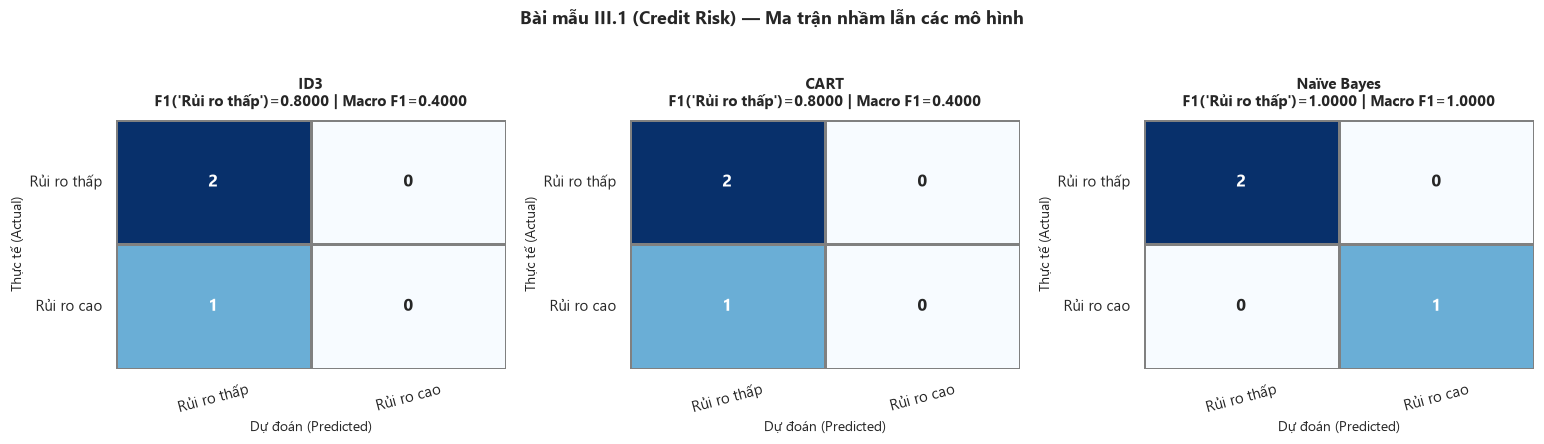

In [4]:
print(f"{STUDENT_NAME} - {MSSV}")
plot_confusion_matrices(
    credit_cm_plots,
    labels=credit_labels,
    title="Bài mẫu III.1 (Credit Risk) — Ma trận nhầm lẫn các mô hình",
    cmap="Blues",
)


**Nhận xét Bài mẫu III.1 (Credit Risk):**
- Hai mô hình cây quyết định **ID3** và **CART** tuy phân nhánh khác nhau ở nhánh `Đã kết hôn` (do đồng hạng giữa `Thu nhập` và `Sở hữu nhà`), nhưng đều cho dự đoán giống nhau trên 3 mẫu kiểm thử (`['Rủi ro thấp', 'Rủi ro thấp', 'Rủi ro thấp']`), đạt **Precision = 2/3 (66,67%)**, **Recall = 100%** và **F-measure = 0,8000** cho lớp dương `'Rủi ro thấp'` (Macro F1 = 0,4000 vì không nhận diện được mẫu âm `'Rủi ro cao'` ở dòng 1).
- Mô hình **Naïve Bayes (Laplace $\alpha = 1$)** dự đoán chính xác cả 3 mẫu kiểm thử, đạt **Precision = 100%**, **Recall = 100%** và **F-measure = 1,0000** (Macro F1 = 1,0000), vượt trội cây quyết định trên tập kiểm thử này.

---
## Phần 2: Bài 1 — Phần IV (Trang 23–25) — Dự đoán doanh số đồ chơi

- **Dữ liệu huấn luyện:** 15 sản phẩm đồ chơi gồm 4 thuộc tính (`Loại`, `Số màu`, `Kích thước`, `Chất liệu`) và biến mục tiêu `Doanh số bán` (`Thấp`: 8 mẫu, `Cao`: 7 mẫu).
- **Dữ liệu kiểm thử (Yêu cầu d–e):** 3 sản phẩm với doanh số thực tế lần lượt là `['Thấp', 'Thấp', 'Cao']`.
- **Sản phẩm mới (Yêu cầu l):** `['Xếp hình', 7, 'Nhỏ', 'Cao su']` — kiểm tra dự đoán của cả ID3, CART và Naïve Bayes.
- **Đánh giá:** Báo cáo đầy đủ ma trận nhầm lẫn, Precision, Recall và F-measure cho **cả hai lớp `'Cao'` và `'Thấp'`** cùng **Macro F1** & **Weighted F1**.

In [5]:
print(f"{STUDENT_NAME} - {MSSV}")

# Dữ liệu huấn luyện và kiểm thử Bài 1 (Trang 24-25)
toys_cols = ["Loại", "Số màu", "Kích thước", "Chất liệu", "Doanh số bán"]
df_toys_train = pd.DataFrame([
    ["Điều khiển", 3, "Nhỏ", "Nhựa PP", "Cao"],
    ["Xếp hình", 5, "Vừa", "Cao su", "Thấp"],
    ["Xếp hình", 7, "To", "Nhựa PP", "Thấp"],
    ["Điều khiển", 5, "Nhỏ", "Cao su", "Thấp"],
    ["Búp bê", 3, "Vừa", "Nhựa PP", "Thấp"],
    ["Điều khiển", 5, "Vừa", "Nhựa PP", "Cao"],
    ["Búp bê", 5, "To", "Nhựa PP", "Cao"],
    ["Điều khiển", 7, "Vừa", "Cao su", "Thấp"],
    ["Xếp hình", 7, "To", "Cao su", "Cao"],
    ["Xếp hình", 3, "To", "Nhựa PP", "Thấp"],
    ["Búp bê", 3, "Nhỏ", "Cao su", "Thấp"],
    ["Xếp hình", 3, "Nhỏ", "Nhựa PP", "Cao"],
    ["Điều khiển", 5, "To", "Cao su", "Thấp"],
    ["Búp bê", 5, "Vừa", "Nhựa PP", "Cao"],
    ["Búp bê", 7, "To", "Nhựa PP", "Cao"],
], columns=toys_cols)

df_toys_test = pd.DataFrame([
    ["Búp bê", 3, "To", "Cao su"],
    ["Xếp hình", 5, "To", "Nhựa PP"],
    ["Điều khiển", 3, "Vừa", "Cao su"],
], columns=toys_cols[:-1])
y_toys_true = ["Thấp", "Thấp", "Cao"]

df_toys_req_l = pd.DataFrame([["Xếp hình", 7, "Nhỏ", "Cao su"]], columns=toys_cols[:-1])
toys_labels = ["Cao", "Thấp"]

# a) Kiểm tra mâu thuẫn
conflicts_toys = check_contradictions(df_toys_train, "Doanh số bán")
print(f"Yêu cầu a) Số dòng mâu thuẫn trong dữ liệu Đồ chơi: {len(conflicts_toys)}")
print("Phân bố lớp tập huấn luyện:", dict(Counter(df_toys_train["Doanh số bán"])))
print(f"Entropy gốc E(S) = {entropy(df_toys_train['Doanh số bán']):.4f} | Gini gốc Gini(S) = {gini_impurity(df_toys_train['Doanh số bán']):.4f}")

# b) & c) Xây dựng ID3 & CART (đa nhánh)
id3_toys = CategoricalDecisionTree("id3", class_order=toys_labels).fit(df_toys_train, "Doanh số bán")
cart_toys = CategoricalDecisionTree("cart", class_order=toys_labels).fit(df_toys_train, "Doanh số bán")

print("\n--- Yêu cầu b & c) Bảng Information Gain (ID3) & Gini Index (CART) tại Nút gốc ---")
display(id3_toys.split_tables_["Root"].drop(columns=["Chi tiết các nhánh"]))

print("\n--- Bảng phân chia tại các nút con (Nhựa PP & Cao su) ---")
for node_path in ["Root -> Chất liệu=Nhựa PP", "Root -> Chất liệu=Cao su"]:
    print(f"\nNút: {node_path}")
    display(cart_toys.split_tables_[node_path].drop(columns=["Chi tiết các nhánh"]))

print("\n--- Các nút xảy ra đồng hạng (phá hòa theo thứ tự cột: Loại > Số màu > Kích thước > Chất liệu) ---")
display(pd.DataFrame(id3_toys.ties_log_ + cart_toys.ties_log_))

print("\n--- Cây quyết định ID3 ---")
print(id3_toys.format_tree())

print("\n--- Cây quyết định CART ---")
print(cart_toys.format_tree())

print("\n--- Tập luật trích xuất từ cây quyết định (ID3 & CART trùng cấu trúc dưới quy tắc thứ tự cột) ---")
for r in cart_toys.extract_rules():
    print(" •", r)

# f), g), h) Xác suất bổ sung
p_xep_hinh = (df_toys_train["Loại"] == "Xếp hình").mean()
sub_thap = df_toys_train[df_toys_train["Doanh số bán"] == "Thấp"]
p_caosu_given_thap = (sub_thap["Chất liệu"] == "Cao su").mean()
print(f"\nYêu cầu f) P(Loại = 'Xếp hình') = {(df_toys_train['Loại'] == 'Xếp hình').sum()}/{len(df_toys_train)} = {p_xep_hinh:.4f}")
print(f"Yêu cầu g) P(Chất liệu = 'Cao su' | Doanh số = 'Thấp') = {(sub_thap['Chất liệu'] == 'Cao su').sum()}/{len(sub_thap)} = {p_caosu_given_thap:.4f}")
print("Yêu cầu h) P(Doanh số = 'Cao' | Loại = 'Điều khiển') = [P(Loại = 'Điều khiển' | Doanh số = 'Cao') * P(Doanh số = 'Cao')] / P(Loại = 'Điều khiển')")


Nguyễn Phạm Bảo Khanh - 6451071033
Yêu cầu a) Số dòng mâu thuẫn trong dữ liệu Đồ chơi: 0
Phân bố lớp tập huấn luyện: {'Cao': 7, 'Thấp': 8}
Entropy gốc E(S) = 0.9968 | Gini gốc Gini(S) = 0.4978

--- Yêu cầu b & c) Bảng Information Gain (ID3) & Gini Index (CART) tại Nút gốc ---


,Thuộc tính,Entropy sau chia,Information Gain (ID3),Gini Index (CART),Giảm Gini
0,Loại,0.9710,0.0258,0.4800,0.0178
1,Số màu,0.9903,0.0065,0.4933,0.0044
2,Kích thước,0.9903,0.0065,0.4933,0.0044
3,Chất liệu,0.8110,0.1858,0.3778,0.1200



--- Bảng phân chia tại các nút con (Nhựa PP & Cao su) ---

Nút: Root -> Chất liệu=Nhựa PP


,Thuộc tính,Entropy sau chia,Information Gain (ID3),Gini Index (CART),Giảm Gini
0,Loại,0.6667,0.2516,0.3148,0.1296
1,Số màu,0.6667,0.2516,0.3333,0.1111
2,Kích thước,0.7505,0.1678,0.3704,0.0741



Nút: Root -> Chất liệu=Cao su


,Thuộc tính,Entropy sau chia,Information Gain (ID3),Gini Index (CART),Giảm Gini
0,Loại,0.3333,0.3167,0.1667,0.1111
1,Số màu,0.3333,0.3167,0.1667,0.1111
2,Kích thước,0.3333,0.3167,0.1667,0.1111



--- Các nút xảy ra đồng hạng (phá hòa theo thứ tự cột: Loại > Số màu > Kích thước > Chất liệu) ---


,Nút,Thuật toán,Điểm tốt nhất,Các thuộc tính đồng hạng,Thuộc tính được chọn,Quy tắc
0,Root -> Chất liệu=Nhựa PP,ID3,0.2516,"Loại, Số màu",Loại,Mặc định theo thứ tự cột
1,Root -> Chất liệu=Cao su,ID3,0.3167,"Loại, Số màu, Kích thước",Loại,Mặc định theo thứ tự cột
2,Root -> Chất liệu=Cao su -> Loại=Xếp hình,ID3,1.0000,"Số màu, Kích thước",Số màu,Mặc định theo thứ tự cột
3,Root -> Chất liệu=Cao su,CART,0.1667,"Loại, Số màu, Kích thước",Loại,Mặc định theo thứ tự cột
4,Root -> Chất liệu=Cao su -> Loại=Xếp hình,CART,0.0000,"Số màu, Kích thước",Số màu,Mặc định theo thứ tự cột



--- Cây quyết định ID3 ---
<Chất liệu> (Gain=0.1858, n=15, {'Cao': 7, 'Thấp': 8})
├── [Chất liệu = Nhựa PP] <Loại> (Gain=0.2516, n=9, {'Cao': 6, 'Thấp': 3})
│   ├── [Loại = Điều khiển] => LÁ: Cao (n=2, {'Cao': 2})
│   ├── [Loại = Xếp hình] <Kích thước> (Gain=0.9183, n=3, {'Thấp': 2, 'Cao': 1})
│   │   ├── [Kích thước = To] => LÁ: Thấp (n=2, {'Thấp': 2})
│   │   └── [Kích thước = Nhỏ] => LÁ: Cao (n=1, {'Cao': 1})
│   └── [Loại = Búp bê] <Số màu> (Gain=0.8113, n=4, {'Thấp': 1, 'Cao': 3})
│       ├── [Số màu = 3] => LÁ: Thấp (n=1, {'Thấp': 1})
│       ├── [Số màu = 5] => LÁ: Cao (n=2, {'Cao': 2})
│       └── [Số màu = 7] => LÁ: Cao (n=1, {'Cao': 1})
└── [Chất liệu = Cao su] <Loại> (Gain=0.3167, n=6, {'Thấp': 5, 'Cao': 1})
    ├── [Loại = Xếp hình] <Số màu> (Gain=1.0000, n=2, {'Thấp': 1, 'Cao': 1})
    │   ├── [Số màu = 5] => LÁ: Thấp (n=1, {'Thấp': 1})
    │   └── [Số màu = 7] => LÁ: Cao (n=1, {'Cao': 1})
    ├── [Loại = Điều khiển] => LÁ: Thấp (n=3, {'Thấp': 3})
    └── [Loại = Búp bê] 

In [6]:
print(f"{STUDENT_NAME} - {MSSV}")

# d), i), l) Dự đoán bằng ID3, CART và Naïve Bayes (Laplace alpha=1)
nb_toys = CategoricalLaplaceNB(alpha=1.0, class_order=toys_labels).fit(df_toys_train, "Doanh số bán")
print("Tiên nghiệm Laplace P(c) = (N_c + 1)/(15 + 2):", {k: round(v, 4) for k, v in nb_toys.priors_.items()})
print("Kích thước tập giá trị |V_i|:", nb_toys.vocab_sizes_)

pred_id3_toys, path_id3_toys = id3_toys.predict_with_paths(df_toys_test)
pred_cart_toys, path_cart_toys = cart_toys.predict_with_paths(df_toys_test)
nb_detail_toys = nb_toys.predict_detail(df_toys_test)
pred_nb_toys = list(nb_detail_toys["Dự đoán NB"])

print("\n--- Chi tiết xác suất Naïve Bayes trên 3 mẫu kiểm thử (Yêu cầu i) ---")
display(nb_detail_toys)

compare_toys_df = df_toys_test.copy()
compare_toys_df["Thực tế"] = y_toys_true
compare_toys_df["Dự đoán ID3"] = pred_id3_toys
compare_toys_df["Dự đoán CART"] = pred_cart_toys
compare_toys_df["Dự đoán Naïve Bayes"] = pred_nb_toys
compare_toys_df["Đường dẫn cây"] = path_cart_toys
print("\n--- Bảng đối chiếu dự đoán tập kiểm thử Đồ chơi (Yêu cầu d–e & i–j) ---")
display(compare_toys_df)
assert len(id3_toys.unseen_fallbacks_) == 0 and len(cart_toys.unseen_fallbacks_) == 0

# Yêu cầu l) Dự đoán sản phẩm mới ['Xếp hình', 7, 'Nhỏ', 'Cao su']
pred_l_id3, path_l_id3 = id3_toys.predict_with_paths(df_toys_req_l)
pred_l_cart, path_l_cart = cart_toys.predict_with_paths(df_toys_req_l)
nb_l_detail = nb_toys.predict_detail(df_toys_req_l)
print("\n--- Yêu cầu l) Dự đoán sản phẩm mới: Loại='Xếp hình', Số màu=7, Kích thước='Nhỏ', Chất liệu='Cao su' ---")
display(nb_l_detail)
print(f" -> ID3 dự đoán: {pred_l_id3[0]} (đường dẫn: {path_l_id3[0]})")
print(f" -> CART dự đoán: {pred_l_cart[0]} (đường dẫn: {path_l_cart[0]})")
print(f" -> Naïve Bayes dự đoán: {nb_l_detail['Dự đoán NB'].iloc[0]}")

# e) & j) Đánh giá Confusion Matrix, Precision, Recall, F-measure
toys_results = {}
toys_cm_plots = {}
for mname, y_pred in [("ID3", pred_id3_toys), ("CART", pred_cart_toys), ("Naïve Bayes", pred_nb_toys)]:
    cm, per_cls, summ = evaluate_predictions(y_toys_true, y_pred, toys_labels)
    toys_results[mname] = (cm, per_cls, summ)
    f1_cao = per_cls.loc[per_cls["Lớp"] == "Cao", "F-measure (F1)"].iloc[0]
    f1_thap = per_cls.loc[per_cls["Lớp"] == "Thấp", "F-measure (F1)"].iloc[0]
    toys_cm_plots[mname] = {
        "cm": cm,
        "subtitle": f"F1('Cao')={f1_cao:.2f}, F1('Thấp')={f1_thap:.2f} | Macro F1={summ['Macro F1']:.2f}",
    }
    print(f"\n=== Kết quả {mname} (Doanh số đồ chơi) ===")
    display(per_cls)
    print(
        f"Accuracy = {summ['Accuracy']:.4f} | Macro P = {summ['Macro Precision']:.4f}, "
        f"Macro R = {summ['Macro Recall']:.4f}, Macro F1 = {summ['Macro F1']:.4f}, "
        f"Weighted F1 = {summ['Weighted F1']:.4f}"
    )


Nguyễn Phạm Bảo Khanh - 6451071033
Tiên nghiệm Laplace P(c) = (N_c + 1)/(15 + 2): {'Cao': 0.4706, 'Thấp': 0.5294}
Kích thước tập giá trị |V_i|: {'Loại': 3, 'Số màu': 3, 'Kích thước': 3, 'Chất liệu': 2}

--- Chi tiết xác suất Naïve Bayes trên 3 mẫu kiểm thử (Yêu cầu i) ---


,Mẫu,Tử số P(X|Cao)P(Cao),Tử số P(X|Thấp)P(Thấp),P(Cao|X) chuẩn hóa,P(Thấp|X) chuẩn hóa,Dự đoán NB
0,1,0.0050,0.0115,0.3047,0.6953,Thấp
1,2,0.0176,0.0102,0.6331,0.3669,Cao
2,3,0.0028,0.0153,0.1560,0.8440,Thấp



--- Bảng đối chiếu dự đoán tập kiểm thử Đồ chơi (Yêu cầu d–e & i–j) ---


,Loại,Số màu,Kích thước,Chất liệu,Thực tế,Dự đoán ID3,Dự đoán CART,Dự đoán Naïve Bayes,Đường dẫn cây
0,Búp bê,3,To,Cao su,Thấp,Thấp,Thấp,Thấp,Chất liệu=Cao su -> Loại=Búp bê
1,Xếp hình,5,To,Nhựa PP,Thấp,Thấp,Thấp,Cao,Chất liệu=Nhựa PP -> Loại=Xếp hình -> Kích thư...
2,Điều khiển,3,Vừa,Cao su,Cao,Thấp,Thấp,Thấp,Chất liệu=Cao su -> Loại=Điều khiển



--- Yêu cầu l) Dự đoán sản phẩm mới: Loại='Xếp hình', Số màu=7, Kích thước='Nhỏ', Chất liệu='Cao su' ---


,Mẫu,Tử số P(X|Cao)P(Cao),Tử số P(X|Thấp)P(Thấp),P(Cao|X) chuẩn hóa,P(Thấp|X) chuẩn hóa,Dự đoán NB
0,1,0.0028,0.0086,0.2474,0.7526,Thấp


... (3 outputs left out)

,Lớp,Precision,Recall,F-measure (F1),Support
0,Cao,0.0000,0.0,0.0,1
1,Thấp,0.6667,1.0,0.8,2


Accuracy = 0.6667 | Macro P = 0.3333, Macro R = 0.5000, Macro F1 = 0.4000, Weighted F1 = 0.5333

=== Kết quả Naïve Bayes (Doanh số đồ chơi) ===


,Lớp,Precision,Recall,F-measure (F1),Support
0,Cao,0.0,0.0,0.0,1
1,Thấp,0.5,0.5,0.5,2


Accuracy = 0.3333 | Macro P = 0.2500, Macro R = 0.2500, Macro F1 = 0.2500, Weighted F1 = 0.3333


Nguyễn Phạm Bảo Khanh - 6451071033


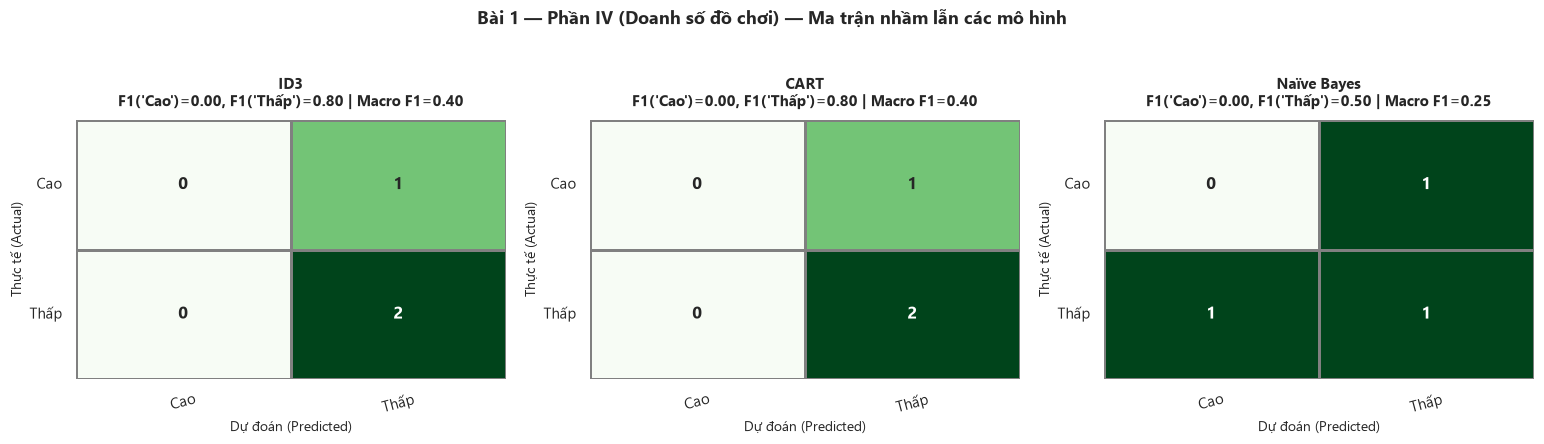

In [7]:
print(f"{STUDENT_NAME} - {MSSV}")
plot_confusion_matrices(
    toys_cm_plots,
    labels=toys_labels,
    title="Bài 1 — Phần IV (Doanh số đồ chơi) — Ma trận nhầm lẫn các mô hình",
    cmap="Greens",
)


**Nhận xét Bài 1 (Doanh số đồ chơi):**
- Với quy tắc phá hòa theo thứ tự cột (`Loại > Số màu > Kích thước > Chất liệu`), cả **ID3** và **CART** đều tạo ra cùng một cây quyết định hoàn chỉnh không gặp nhánh chưa thấy nào trên tập kiểm thử lẫn sản phẩm mới (Yêu cầu l).
- Trên 3 mẫu kiểm thử, **ID3 & CART** đạt **Accuracy = 66,67%** (`F1('Thấp') = 0,8000`, `F1('Cao') = 0,0000`, `Macro F1 = 0,4000`, `Weighted F1 = 0,5333`), cao hơn **Naïve Bayes** (**Accuracy = 33,33%**, `F1('Thấp') = 0,5000`, `F1('Cao') = 0,0000`, `Macro F1 = 0,2500`, `Weighted F1 = 0,3333`).
- Nguyên nhân là ở mẫu 2 (`Xếp hình, 5, To, Nhựa PP`), giả thiết độc lập của Naïve Bayes bị chi phối mạnh bởi xác suất biên `P(Nhựa PP | Cao) = 7/9` nên dự đoán nhầm sang `Cao`, trong khi cây quyết định bắt được tương tác phối hợp `Chất liệu=Nhựa PP -> Loại=Xếp hình -> Kích thước=To => Thấp`.
- Ở **Yêu cầu l** (`Xếp hình, 7, Nhỏ, Cao su`), **ID3/CART** dự đoán **`Cao`** (theo nhánh `Chất liệu=Cao su -> Loại=Xếp hình -> Số màu=7`), trong khi **Naïve Bayes** dự đoán **`Thấp`** (vì sản phẩm làm bằng `Cao su`, vốn chiếm 5/6 mẫu `Thấp` trong tập huấn luyện).

---
## Phần 3: Bài 2 — Phần IV (Trang 25–26) — Phân tích cảm xúc (*Sentiment Analysis*)

- **Dữ liệu huấn luyện:** 14 trạng thái mạng xã hội với 6 thuộc tính tần suất từ khóa (`giảm`, `người`, `chuyển`, `yêu`, `vừa`, `đi`) và thuộc tính phân lớp đa lớp `Cảm xúc` (`tốt`: 5, `xấu`: 5, `bình thường`: 4).
- **Dữ liệu kiểm thử (Yêu cầu c–d):** 4 trạng thái với cảm xúc thực tế lần lượt là `['xấu', 'tốt', 'bình thường', 'tốt']`.
- **Đánh giá:** Lập **ma trận nhầm lẫn 3×3**, tính Precision, Recall, F-measure từng lớp cùng **Macro F1** và **Weighted F1**; đồng thời ghi nhận rõ các nút đồng hạng (*tie-breaking*) trong CART/ID3.

In [8]:
print(f"{STUDENT_NAME} - {MSSV}")

# Dữ liệu huấn luyện và kiểm thử Bài 2 (Trang 25-26)
sent_cols = ["giảm", "người", "chuyển", "yêu", "vừa", "đi", "Cảm xúc"]
df_sent_train = pd.DataFrame([
    ["0..5", "11..20", ">20", "11..20", ">20", "0..5", "tốt"],
    ["11..20", "6..10", "6..10", "0..5", "11..20", "11..20", "tốt"],
    ["6..10", "0..5", "6..10", "11..20", "0..5", "6..10", "xấu"],
    [">20", "0..5", "11..20", "6..10", "0..5", ">20", "bình thường"],
    ["0..5", ">20", "11..20", "0..5", "6..10", "0..5", "xấu"],
    ["0..5", "6..10", "0..5", "0..5", "11..20", "11..20", "xấu"],
    ["0..5", "6..10", "11..20", "0..5", "6..10", "0..5", "tốt"],
    ["11..20", ">20", "0..5", "11..20", "0..5", "11..20", "bình thường"],
    ["0..5", "0..5", "6..10", "6..10", "6..10", ">20", "tốt"],
    ["11..20", "0..5", "11..20", "11..20", "0..5", "11..20", "tốt"],
    [">20", "6..10", "0..5", "0..5", "0..5", "6..10", "xấu"],
    ["0..5", "0..5", "11..20", "0..5", "11..20", ">20", "bình thường"],
    ["6..10", "11..20", "6..10", ">20", "0..5", "6..10", "bình thường"],
    ["11..20", "6..10", ">20", "11..20", "0..5", "0..5", "xấu"],
], columns=sent_cols)

df_sent_test = pd.DataFrame([
    ["0..5", "6..10", "0..5", "11..20", "6..10", "0..5"],
    ["0..5", "0..5", "6..10", "0..5", "11..20", ">20"],
    ["6..10", "0..5", "11..20", ">20", "6..10", "6..10"],
    ["6..10", "11..20", "6..10", "6..10", ">20", "0..5"],
], columns=sent_cols[:-1])
y_sent_true = ["xấu", "tốt", "bình thường", "tốt"]
sent_labels = ["tốt", "xấu", "bình thường"]

# a) Kiểm tra mâu thuẫn
conflicts_sent = check_contradictions(df_sent_train, "Cảm xúc")
print(f"Yêu cầu a) Số dòng mâu thuẫn trong dữ liệu Cảm xúc: {len(conflicts_sent)}")
print("Phân bố lớp tập huấn luyện:", dict(Counter(df_sent_train["Cảm xúc"])))
print(f"Entropy gốc E(S) = {entropy(df_sent_train['Cảm xúc']):.4f} | Gini gốc Gini(S) = {gini_impurity(df_sent_train['Cảm xúc']):.4f}")

# b) Huấn luyện CART (và ID3 để đối chiếu toàn diện)
cart_sent = CategoricalDecisionTree("cart", class_order=sent_labels).fit(df_sent_train, "Cảm xúc")
id3_sent = CategoricalDecisionTree("id3", class_order=sent_labels).fit(df_sent_train, "Cảm xúc")

print("\n--- Yêu cầu b) Bảng Gini Index (CART) & Information Gain (ID3) tại Nút gốc ---")
display(cart_sent.split_tables_["Root"].drop(columns=["Chi tiết các nhánh"]))

print("\n--- Các nút xảy ra đồng hạng trong cây CART (phá hòa theo thứ tự cột) ---")
display(pd.DataFrame(cart_sent.ties_log_))

print("\n--- Cây quyết định CART (đa nhánh) ---")
print(cart_sent.format_tree())

print("\n--- Tập luật trích xuất từ cây CART ---")
for r in cart_sent.extract_rules():
    print(" •", r)


Nguyễn Phạm Bảo Khanh - 6451071033
Yêu cầu a) Số dòng mâu thuẫn trong dữ liệu Cảm xúc: 0
Phân bố lớp tập huấn luyện: {'tốt': 5, 'xấu': 5, 'bình thường': 4}
Entropy gốc E(S) = 1.5774 | Gini gốc Gini(S) = 0.6633

--- Yêu cầu b) Bảng Gini Index (CART) & Information Gain (ID3) tại Nút gốc ---


,Thuộc tính,Entropy sau chia,Information Gain (ID3),Gini Index (CART),Giảm Gini
0,giảm,1.3396,0.2378,0.5833,0.0799
1,người,1.1760,0.4014,0.5429,0.1204
2,chuyển,1.3118,0.2657,0.5738,0.0895
3,yêu,1.3118,0.2657,0.5619,0.1014
4,vừa,1.2608,0.3166,0.5442,0.1190
5,đi,1.1078,0.4696,0.5119,0.1514



--- Các nút xảy ra đồng hạng trong cây CART (phá hòa theo thứ tự cột) ---


,Nút,Thuật toán,Điểm tốt nhất,Các thuộc tính đồng hạng,Thuộc tính được chọn,Quy tắc
0,Root -> đi=0..5,CART,0.25,"người, vừa",người,Mặc định theo thứ tự cột
1,Root -> đi=0..5 -> người=6..10,CART,0.00,"giảm, chuyển, yêu, vừa",giảm,Mặc định theo thứ tự cột
2,Root -> đi=11..20,CART,0.25,"người, chuyển",người,Mặc định theo thứ tự cột
3,Root -> đi=11..20 -> người=6..10,CART,0.00,"giảm, chuyển",giảm,Mặc định theo thứ tự cột
4,Root -> đi=6..10,CART,0.00,"người, yêu",người,Mặc định theo thứ tự cột
5,Root -> đi=>20,CART,0.00,"chuyển, vừa",chuyển,Mặc định theo thứ tự cột



--- Cây quyết định CART (đa nhánh) ---
<đi> (Gini=0.5119, n=14, {'tốt': 5, 'xấu': 5, 'bình thường': 4})
├── [đi = 0..5] <người> (Gini=0.2500, n=4, {'tốt': 2, 'xấu': 2})
│   ├── [người = 11..20] => LÁ: tốt (n=1, {'tốt': 1})
│   ├── [người = >20] => LÁ: xấu (n=1, {'xấu': 1})
│   └── [người = 6..10] <giảm> (Gini=0.0000, n=2, {'tốt': 1, 'xấu': 1})
│       ├── [giảm = 0..5] => LÁ: tốt (n=1, {'tốt': 1})
│       └── [giảm = 11..20] => LÁ: xấu (n=1, {'xấu': 1})
├── [đi = 11..20] <người> (Gini=0.2500, n=4, {'tốt': 2, 'xấu': 1, 'bình thường': 1})
│   ├── [người = 6..10] <giảm> (Gini=0.0000, n=2, {'tốt': 1, 'xấu': 1})
│   │   ├── [giảm = 11..20] => LÁ: tốt (n=1, {'tốt': 1})
│   │   └── [giảm = 0..5] => LÁ: xấu (n=1, {'xấu': 1})
│   ├── [người = >20] => LÁ: bình thường (n=1, {'bình thường': 1})
│   └── [người = 0..5] => LÁ: tốt (n=1, {'tốt': 1})
├── [đi = 6..10] <người> (Gini=0.0000, n=3, {'xấu': 2, 'bình thường': 1})
│   ├── [người = 0..5] => LÁ: xấu (n=1, {'xấu': 1})
│   ├── [người = 6..10] => 

In [9]:
print(f"{STUDENT_NAME} - {MSSV}")

# c) & d) Dự đoán bằng CART (ID3) và Naïve Bayes (Laplace alpha=1)
nb_sent = CategoricalLaplaceNB(alpha=1.0, class_order=sent_labels).fit(df_sent_train, "Cảm xúc")
print("Tiên nghiệm Laplace P(c) = (N_c + 1)/(14 + 3):", {k: round(v, 4) for k, v in nb_sent.priors_.items()})
print("Kích thước tập giá trị |V_i|:", nb_sent.vocab_sizes_)

pred_id3_sent, path_id3_sent = id3_sent.predict_with_paths(df_sent_test)
pred_cart_sent, path_cart_sent = cart_sent.predict_with_paths(df_sent_test)
nb_detail_sent = nb_sent.predict_detail(df_sent_test)
pred_nb_sent = list(nb_detail_sent["Dự đoán NB"])

print("\n--- Chi tiết xác suất Naïve Bayes trên 4 trạng thái kiểm thử ---")
display(nb_detail_sent)

compare_sent_df = df_sent_test.copy()
compare_sent_df["Thực tế"] = y_sent_true
compare_sent_df["Dự đoán ID3"] = pred_id3_sent
compare_sent_df["Dự đoán CART"] = pred_cart_sent
compare_sent_df["Dự đoán Naïve Bayes"] = pred_nb_sent
compare_sent_df["Đường dẫn CART"] = path_cart_sent
print("\n--- Bảng đối chiếu dự đoán tập kiểm thử Phân tích cảm xúc ---")
display(compare_sent_df)
assert len(cart_sent.unseen_fallbacks_) == 0 and len(id3_sent.unseen_fallbacks_) == 0

# Tính ma trận nhầm lẫn 3x3 & các độ đo Precision, Recall, F-measure
sent_results = {}
sent_cm_plots = {}
for mname, y_pred in [("ID3", pred_id3_sent), ("CART", pred_cart_sent), ("Naïve Bayes", pred_nb_sent)]:
    cm, per_cls, summ = evaluate_predictions(y_sent_true, y_pred, sent_labels)
    sent_results[mname] = (cm, per_cls, summ)
    sent_cm_plots[mname] = {
        "cm": cm,
        "subtitle": f"Macro F1={summ['Macro F1']:.4f} | Weighted F1={summ['Weighted F1']:.4f}",
    }
    print(f"\n=== Kết quả {mname} (Phân tích cảm xúc — Ma trận 3x3) ===")
    display(per_cls)
    print(
        f"Accuracy = {summ['Accuracy']:.4f} | Macro P = {summ['Macro Precision']:.4f}, "
        f"Macro R = {summ['Macro Recall']:.4f}, Macro F1 = {summ['Macro F1']:.4f}, "
        f"Weighted F1 = {summ['Weighted F1']:.4f}"
    )

# Phân tích độ nhạy phá hòa (Tie-breaking sensitivity) cho CART trên Bài 2
def enumerate_cart_f1_range(df_train, df_test, y_true, target_col, labels):
    features = [c for c in df_train.columns if c != target_col]

    def build_all(sub, rem):
        lbls = list(sub[target_col])
        cnt = Counter(lbls)
        if len(cnt) == 1:
            return [lbls[0]]
        if not rem:
            return [cnt.most_common(1)[0][0]]
        tbl = compute_split_metrics(sub, rem, target_col)
        best = tbl["Gini Index (CART)"].min()
        tied = list(tbl.loc[(tbl["Gini Index (CART)"] - best).abs() < 1e-12, "Thuộc tính"])
        trees = []
        for ch in tied:
            r2 = [f for f in rem if f != ch]
            opts = {v: build_all(s, r2) for v, s in sub.groupby(ch, sort=False)}
            keys = list(opts.keys())
            for combo in itertools.product(*(opts[k] for k in keys)):
                trees.append({"f": ch, "maj": cnt.most_common(1)[0][0], "b": dict(zip(keys, combo))})
        return trees

    def pred_one(t, row):
        if isinstance(t, str):
            return t
        v = row[t["f"]]
        return pred_one(t["b"][v], row) if v in t["b"] else t["maj"]

    all_t = build_all(df_train, features)
    macro_f1s = []
    for t in all_t:
        yp = [pred_one(t, r) for _, r in df_test.iterrows()]
        _, _, f1_m, _ = precision_recall_fscore_support(y_true, yp, labels=labels, average="macro", zero_division=0)
        macro_f1s.append(float(f1_m))
    return len(all_t), min(macro_f1s), max(macro_f1s)

n_tie_trees, min_f1_tie, max_f1_tie = enumerate_cart_f1_range(df_sent_train, df_sent_test, y_sent_true, "Cảm xúc", sent_labels)
print(f"\n[Phân tích phá hòa CART]: Tồn tại {n_tie_trees} cây đồng hạng Gini; Macro F1 dao động từ {min_f1_tie:.4f} đến {max_f1_tie:.4f} (cây chuẩn theo thứ tự cột đạt {sent_results['CART'][2]['Macro F1']:.4f}).")


Nguyễn Phạm Bảo Khanh - 6451071033
Tiên nghiệm Laplace P(c) = (N_c + 1)/(14 + 3): {'tốt': 0.3529, 'xấu': 0.3529, 'bình thường': 0.2941}
Kích thước tập giá trị |V_i|: {'giảm': 4, 'người': 4, 'chuyển': 4, 'yêu': 4, 'vừa': 4, 'đi': 4}

--- Chi tiết xác suất Naïve Bayes trên 4 trạng thái kiểm thử ---


,Mẫu,Tử số P(X|tốt)P(tốt),Tử số P(X|xấu)P(xấu),Tử số P(X|bình thường)P(bình thường),P(tốt|X) chuẩn hóa,P(xấu|X) chuẩn hóa,P(bình thường|X) chuẩn hóa,Dự đoán NB
0,1,2.1518e-04,4.3035e-04,8.9758e-06,0.3288,0.6575,0.0137,xấu
1,2,2.8690e-04,6.3756e-05,1.6156e-04,0.5601,0.1245,0.3154,tốt
2,3,1.7931e-05,3.1878e-05,8.0782e-05,0.1373,0.2441,0.6186,bình thường
3,4,4.7817e-05,7.9695e-06,1.7952e-05,0.6485,0.1081,0.2435,tốt



--- Bảng đối chiếu dự đoán tập kiểm thử Phân tích cảm xúc ---


,giảm,người,chuyển,yêu,vừa,đi,Thực tế,Dự đoán ID3,Dự đoán CART,Dự đoán Naïve Bayes,Đường dẫn CART
0,0..5,6..10,0..5,11..20,6..10,0..5,xấu,tốt,tốt,xấu,đi=0..5 -> người=6..10 -> giảm=0..5
1,0..5,0..5,6..10,0..5,11..20,>20,tốt,tốt,tốt,tốt,đi=>20 -> chuyển=6..10
2,6..10,0..5,11..20,>20,6..10,6..10,bình thường,xấu,xấu,bình thường,đi=6..10 -> người=0..5
3,6..10,11..20,6..10,6..10,>20,0..5,tốt,tốt,tốt,tốt,đi=0..5 -> người=11..20



=== Kết quả ID3 (Phân tích cảm xúc — Ma trận 3x3) ===


,Lớp,Precision,Recall,F-measure (F1),Support
0,tốt,0.6667,1.0,0.8,2
1,xấu,0.0000,0.0,0.0,1
2,bình thường,0.0000,0.0,0.0,1


... (3 outputs left out)


=== Kết quả Naïve Bayes (Phân tích cảm xúc — Ma trận 3x3) ===


,Lớp,Precision,Recall,F-measure (F1),Support
0,tốt,1.0,1.0,1.0,2
1,xấu,1.0,1.0,1.0,1
2,bình thường,1.0,1.0,1.0,1


Accuracy = 1.0000 | Macro P = 1.0000, Macro R = 1.0000, Macro F1 = 1.0000, Weighted F1 = 1.0000



[Phân tích phá hòa CART]: Tồn tại 120 cây đồng hạng Gini; Macro F1 dao động từ 0.1667 đến 1.0000 (cây chuẩn theo thứ tự cột đạt 0.2667).


Nguyễn Phạm Bảo Khanh - 6451071033


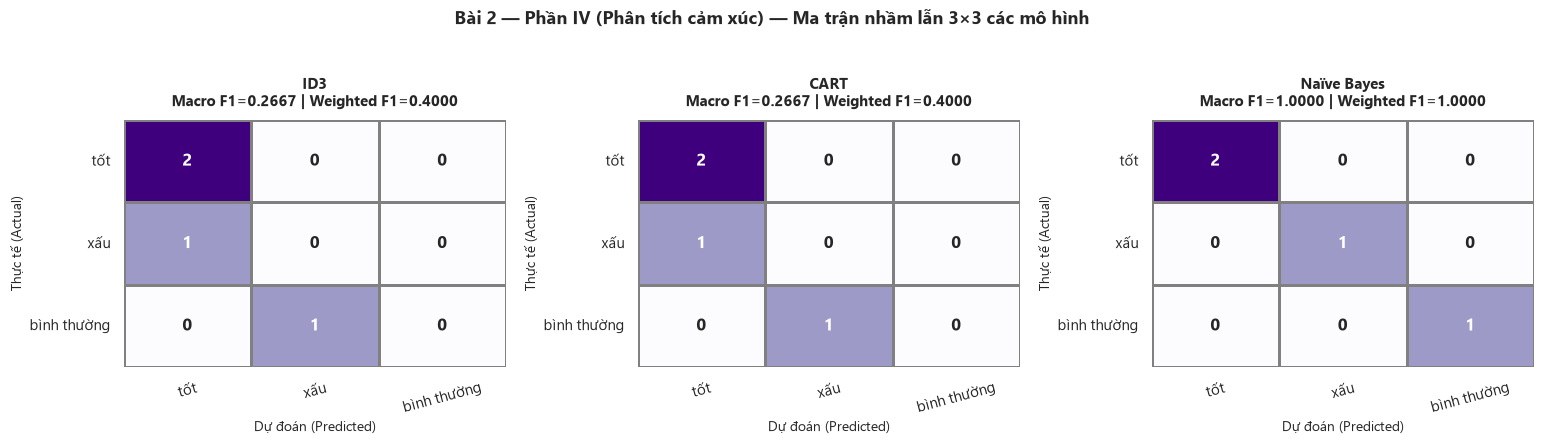

In [10]:
print(f"{STUDENT_NAME} - {MSSV}")
plot_confusion_matrices(
    sent_cm_plots,
    labels=sent_labels,
    title="Bài 2 — Phần IV (Phân tích cảm xúc) — Ma trận nhầm lẫn 3×3 các mô hình",
    cmap="Purples",
)


**Nhận xét Bài 2 (Phân tích cảm xúc — Yêu cầu d & e):**
- **So sánh hiệu năng:** Cây quyết định **CART** (và **ID3**) có nút gốc rõ ràng là `'đi'` ($\text{Gini}=0,5119$), nhưng từ tầng thứ 2 trở đi tập con chỉ còn 2–4 mẫu nên xuất hiện tới 6 nút đồng hạng chỉ số Gini; theo quy tắc thứ tự cột, cả CART và ID3 chỉ dự đoán đúng 2/4 mẫu (`'tốt'`), đạt **Accuracy = 50,00%**, **Macro F1 = 0,2667** và **Weighted F1 = 0,4000**. Ngược lại, **Naïve Bayes (Laplace $\alpha = 1$)** kết hợp đồng thời thông tin từ cả 6 từ khóa và đạt **Accuracy = 100%**, **Precision = 1,0000**, **Recall = 1,0000**, **Macro F1 = 1,0000**, **Weighted F1 = 1,0000** trên cả 3 lớp (`'tốt'`, `'xấu'`, `'bình thường'`).
- **Kết luận (Yêu cầu d):** Với bài toán phân tích văn bản nhiều thuộc tính rời rạc và tập mẫu nhỏ, Naïve Bayes ít bị quá khớp (*overfitting*) hơn cây quyết định vì không chia nhỏ dữ liệu thành các nhánh chỉ còn 1–2 mẫu dễ bị đồng hạng ngẫu nhiên.
- **Ứng dụng thực tiễn (Yêu cầu e):** Việc nắm bắt cảm xúc người dùng mạng xã hội giúp doanh nghiệp theo dõi phản hồi thương hiệu theo thời gian thực, phát hiện sớm khủng hoảng truyền thông (khi tỉ lệ nhãn `'xấu'` tăng đột biến), cải thiện chất lượng sản phẩm/dịch vụ và cá nhân hóa chiến dịch chăm sóc khách hàng.

---
## Phần 4: Tổng hợp và Trực quan hóa giá trị F-measure trên cả 3 bài tập cơ bản (Bài 2 — Trang 32)

Tổng hợp và trực quan hóa chỉ số **Precision**, **Recall**, **F-measure ($F_1$)** theo từng lớp, **Macro F1** và **Weighted F1** của cả 3 mô hình (**ID3**, **CART**, **Naïve Bayes**) trên cả 3 bài tập cơ bản.

In [11]:
print(f"{STUDENT_NAME} - {MSSV}")

summary_rows = []
per_class_all_rows = []

exercise_bundles = [
    ("1. Bài mẫu III.1 (Credit Risk)", credit_results, "Rủi ro thấp"),
    ("2. Bài 1 - IV.1 (Doanh số đồ chơi)", toys_results, None),
    ("3. Bài 2 - IV.2 (Phân tích cảm xúc)", sent_results, None),
]

for ex_name, res_dict, pos_cls in exercise_bundles:
    for mname, (cm, per_cls, summ) in res_dict.items():
        f1_per_cls_str = " / ".join(f"{r['Lớp']}: {r['F-measure (F1)']:.2f}" for _, r in per_cls.iterrows())
        summary_rows.append({
            "Bài tập": ex_name,
            "Mô hình": mname,
            "Số mẫu test": int(per_cls["Support"].sum()),
            "Accuracy": summ["Accuracy"],
            "Macro Precision": summ["Macro Precision"],
            "Macro Recall": summ["Macro Recall"],
            "Macro F1": summ["Macro F1"],
            "Weighted F1": summ["Weighted F1"],
            "F-measure từng lớp": f1_per_cls_str,
        })
        for _, r in per_cls.iterrows():
            short_ex = ex_name.split("(")[0].strip()
            per_class_all_rows.append({
                "Bài tập": ex_name,
                "Bài tập - Lớp": f"{short_ex}\n({r['Lớp']})",
                "Mô hình": mname,
                "Lớp": r["Lớp"],
                "Precision": r["Precision"],
                "Recall": r["Recall"],
                "F-measure (F1)": r["F-measure (F1)"],
                "Support": int(r["Support"]),
            })

summary_df = pd.DataFrame(summary_rows)
per_class_all_df = pd.DataFrame(per_class_all_rows)

print("=== BẢNG TỔNG HỢP F-MEASURE TRÊN CẢ 3 BÀI TẬP CƠ BẢN (TRANG 32) ===")
display(summary_df)

print("\n=== BẢNG CHI TIẾT PRECISION, RECALL & F-MEASURE THEO TỪNG LỚP ===")
display(per_class_all_df.drop(columns=["Bài tập - Lớp"]))


Nguyễn Phạm Bảo Khanh - 6451071033
=== BẢNG TỔNG HỢP F-MEASURE TRÊN CẢ 3 BÀI TẬP CƠ BẢN (TRANG 32) ===


,Bài tập,Mô hình,Số mẫu test,Accuracy,Macro Precision,Macro Recall,Macro F1,Weighted F1,F-measure từng lớp
0,1. Bài mẫu III.1 (Credit Risk),ID3,3,0.6667,0.3333,0.5000,0.4000,0.5333,Rủi ro thấp: 0.80 / Rủi ro cao: 0.00
1,1. Bài mẫu III.1 (Credit Risk),CART,3,0.6667,0.3333,0.5000,0.4000,0.5333,Rủi ro thấp: 0.80 / Rủi ro cao: 0.00
2,1. Bài mẫu III.1 (Credit Risk),Naïve Bayes,3,1.0000,1.0000,1.0000,1.0000,1.0000,Rủi ro thấp: 1.00 / Rủi ro cao: 1.00
3,2. Bài 1 - IV.1 (Doanh số đồ chơi),ID3,3,0.6667,0.3333,0.5000,0.4000,0.5333,Cao: 0.00 / Thấp: 0.80
4,2. Bài 1 - IV.1 (Doanh số đồ chơi),CART,3,0.6667,0.3333,0.5000,0.4000,0.5333,Cao: 0.00 / Thấp: 0.80
5,2. Bài 1 - IV.1 (Doanh số đồ chơi),Naïve Bayes,3,0.3333,0.2500,0.2500,0.2500,0.3333,Cao: 0.00 / Thấp: 0.50
6,3. Bài 2 - IV.2 (Phân tích cảm xúc),ID3,4,0.5000,0.2222,0.3333,0.2667,0.4000,tốt: 0.80 / xấu: 0.00 / bình thường: 0.00
7,3. Bài 2 - IV.2 (Phân tích cảm xúc),CART,4,0.5000,0.2222,0.3333,0.2667,0.4000,tốt: 0.80 / xấu: 0.00 / bình thường: 0.00
8,3. Bài 2 - IV.2 (Phân tích cảm xúc),Naïve Bayes,4,1.0000,1.0000,1.0000,1.0000,1.0000,tốt: 1.00 / xấu: 1.00 / bình thường: 1.00



=== BẢNG CHI TIẾT PRECISION, RECALL & F-MEASURE THEO TỪNG LỚP ===


,Bài tập,Mô hình,Lớp,Precision,Recall,F-measure (F1),Support
0,1. Bài mẫu III.1 (Credit Risk),ID3,Rủi ro thấp,0.6667,1.0,0.8,2
1,1. Bài mẫu III.1 (Credit Risk),ID3,Rủi ro cao,0.0000,0.0,0.0,1
2,1. Bài mẫu III.1 (Credit Risk),CART,Rủi ro thấp,0.6667,1.0,0.8,2
3,1. Bài mẫu III.1 (Credit Risk),CART,Rủi ro cao,0.0000,0.0,0.0,1
4,1. Bài mẫu III.1 (Credit Risk),Naïve Bayes,Rủi ro thấp,1.0000,1.0,1.0,2
5,1. Bài mẫu III.1 (Credit Risk),Naïve Bayes,Rủi ro cao,1.0000,1.0,1.0,1
6,2. Bài 1 - IV.1 (Doanh số đồ chơi),ID3,Cao,0.0000,0.0,0.0,1
7,2. Bài 1 - IV.1 (Doanh số đồ chơi),ID3,Thấp,0.6667,1.0,0.8,2
8,2. Bài 1 - IV.1 (Doanh số đồ chơi),CART,Cao,0.0000,0.0,0.0,1
9,2. Bài 1 - IV.1 (Doanh số đồ chơi),CART,Thấp,0.6667,1.0,0.8,2


Nguyễn Phạm Bảo Khanh - 6451071033


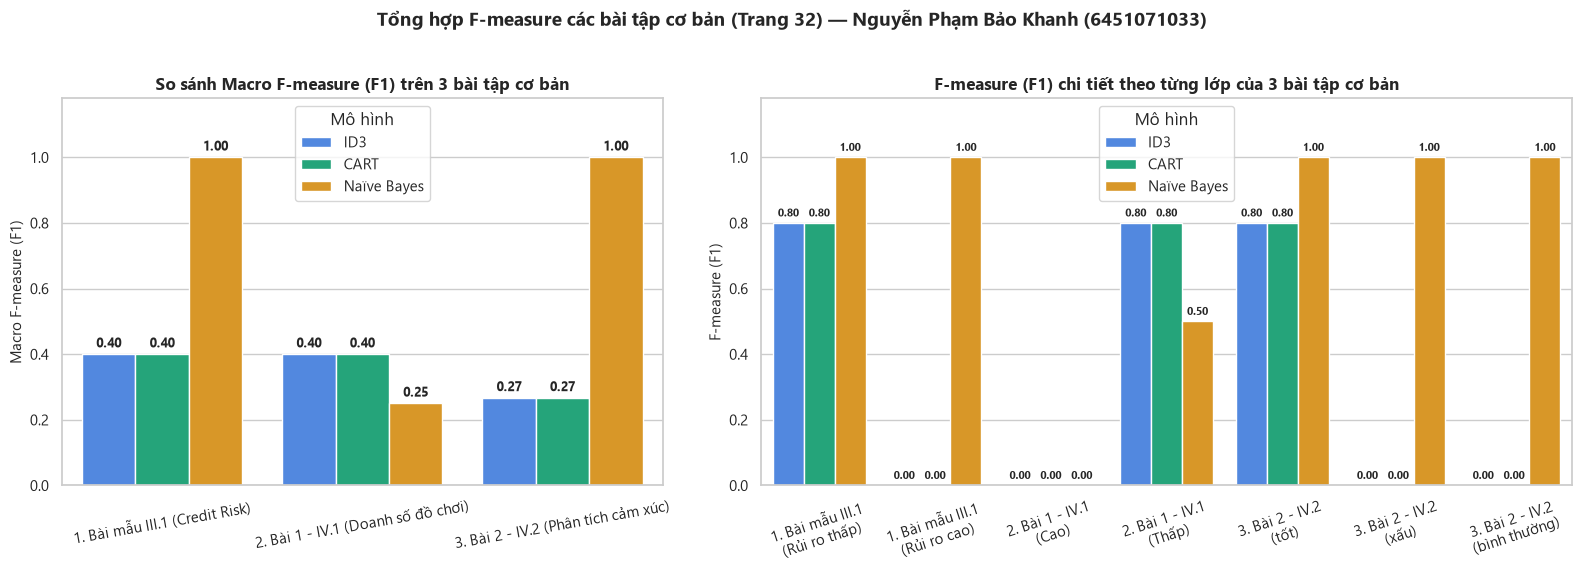

In [12]:
print(f"{STUDENT_NAME} - {MSSV}")

fig, axes = plt.subplots(1, 2, figsize=(16, 5.6), gridspec_kw={"width_ratios": [1.0, 1.35]})
palette = {"ID3": "#3b82f6", "CART": "#10b981", "Naïve Bayes": "#f59e0b"}

# Biểu đồ 1: So sánh Macro F1 trên 3 bài tập cơ bản
sns.barplot(
    data=summary_df,
    x="Bài tập",
    y="Macro F1",
    hue="Mô hình",
    palette=palette,
    ax=axes[0],
)
axes[0].set_title("So sánh Macro F-measure (F1) trên 3 bài tập cơ bản", fontsize=12, fontweight="bold")
axes[0].set_xlabel("")
axes[0].set_ylabel("Macro F-measure (F1)", fontsize=11)
axes[0].set_ylim(0, 1.18)
axes[0].tick_params(axis="x", rotation=10)
for container in axes[0].containers:
    axes[0].bar_label(container, fmt="%.2f", padding=3, fontsize=9, fontweight="bold")

# Biểu đồ 2: F-measure chi tiết cho từng lớp của cả 3 bài tập
sns.barplot(
    data=per_class_all_df,
    x="Bài tập - Lớp",
    y="F-measure (F1)",
    hue="Mô hình",
    palette=palette,
    ax=axes[1],
)
axes[1].set_title("F-measure (F1) chi tiết theo từng lớp của 3 bài tập cơ bản", fontsize=12, fontweight="bold")
axes[1].set_xlabel("")
axes[1].set_ylabel("F-measure (F1)", fontsize=11)
axes[1].set_ylim(0, 1.18)
axes[1].tick_params(axis="x", rotation=18)
for container in axes[1].containers:
    axes[1].bar_label(container, fmt="%.2f", padding=3, fontsize=8, fontweight="bold")

fig.suptitle(f"Tổng hợp F-measure các bài tập cơ bản (Trang 32) — {STUDENT_NAME} ({MSSV})", fontsize=13.5, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()


### Kết luận chung (Bài 2 — Trang 32)
1. **Bài mẫu III.1 (Credit Risk):** Kiểm chứng chính xác kết quả tài liệu hướng dẫn: **ID3 & CART** đạt `Precision = 2/3 (0,6667)`, `Recall = 1,0000`, **`F-measure('Rủi ro thấp') = 0,8000`** (`Macro F1 = 0,4000`, `Weighted F1 = 0,5333`), trong khi **Naïve Bayes (Laplace)** đạt **`F-measure('Rủi ro thấp') = 1,0000`** (`Macro F1 = 1,0000`).
2. **Bài 1 — Phần IV (Doanh số đồ chơi):** Với quy tắc phá hòa theo thứ tự cột, **ID3 & CART** đạt **`F-measure('Thấp') = 0,8000`**, `F-measure('Cao') = 0,0000`, **`Macro F1 = 0,4000`** (`Weighted F1 = 0,5333`), vượt trội **Naïve Bayes** (`F-measure('Thấp') = 0,5000`, `F-measure('Cao') = 0,0000`, **`Macro F1 = 0,2500`**, `Weighted F1 = 0,3333`) nhờ cây quyết định nắm bắt tương tác giữa `Chất liệu`, `Loại` và `Kích thước`.
3. **Bài 2 — Phần IV (Phân tích cảm xúc):** Với tập mẫu nhỏ (14 dòng) nhưng có 6 thuộc tính rời rạc, **CART & ID3** xuất hiện nhiều nhánh đồng hạng ở tầng sâu và chỉ đạt **`Macro F1 = 0,2667`**, **`Weighted F1 = 0,4000`** (`F1('tốt') = 0,80`, `F1('xấu') = 0,00`, `F1('bình thường') = 0,00`), trong khi **Naïve Bayes (Laplace)** đạt **`F-measure = 1,0000`** trên cả 3 lớp (`Macro F1 = 1,0000`, `Weighted F1 = 1,0000`).
4. **Ý nghĩa của F-measure:** Khi phân lớp trên dữ liệu kích thước nhỏ hoặc có lớp không được dự đoán đúng nào (`Precision`/`Recall` bằng 0), chỉ số **F-measure** (trung bình điều hòa) cùng **Macro F1 / Weighted F1** phản ánh đầy đủ chất lượng phân lớp trên từng nhãn thay vì chỉ nhìn vào `Accuracy`.